In [11]:
import allel # use pmr env
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import socket as socket
import os as os
import sys as sys
import h5py
import multiprocessing as mp
import itertools as it

In [4]:
%%time

path_vcf = "/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/high_cov/bricei_only_variants_chr.maf05.vcf.gz"
path_h5 = "/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/high_cov/bricei_only_variants_chr.maf05.h5"

print(f"Converting VCF to HDF5...")
allel.vcf_to_hdf5(input=path_vcf, output=path_h5, 
                  fields = ['variants/*', 'calldata/*', "samples"], 
                  types = {"samples":"S120", "calldata/GT":np.int8,
                           "calldata/GP":np.float32, "calldata/AD":np.int16}, 
                  buffer_size=20000,
                  chunk_length = 10000, chunk_width=8,
                  compression="gzip") # Do the conversion to hdf5. Takes hours
print("Finished conversion to hdf5!")

Converting VCF to HDF5...
Finished conversion to hdf5!
CPU times: user 14.1 s, sys: 758 ms, total: 14.8 s
Wall time: 14.9 s


In [5]:
### Fraction derived alleles
def ad_to_ph(ad, dp=[], miss_val=-1):
    """Transform allele depths to pseudo-haploid genotypes
    ad: Allele Counts in formant [n_snps, n_iids, 2]
    dp: Depths [n_snps, n_iids], if not given, calculate from ad
    Return ph: [n_snps, n_iids], pseudo-haploid genotypes 0,1"""
    if len(dp)==0:
        dp = np.sum(ad, axis=2)
    idx_miss = (dp == 0) # Find non covered SNPs
    dp[idx_miss] = 1 # Temp fix for division
    p = ad[:,:,1] / dp # Chance of derived allele
    
    ph = (np.random.random(size=np.shape(p)) < p).astype(np.int8) # Where derived
    ph[idx_miss] = miss_val
    return ph


### Calculate PMRs
def pw_mm_rate(g1, g2, val_missing=-1):
    """ Calculate Pairwise Mismatch Rate between two samples.
    g1, g2: Array of genotype values
    val_missing: Value of Missing data.
    Return PMR, # mismatches, # SNPs covered in both"""
    idx_both = (g1!=val_missing) & (g2!=val_missing)
    snps = np.sum(idx_both)
    mms = np.sum(idx_both * (g1 != g2)) 
    
    pw_mm_rate = mms / snps
    return pw_mm_rate, mms, snps

def pw_mm_rates_iids(gts=[], iids=[], val_missing=-1):
    """Calculate all possible pw. mismatch rates for list of iids
    gt: Genotype Matrix [#IIDs x #SNPs]
    dfj: Janno Dataframe
    val_missing: Value of Missing data"""

    n= len(iids)
    res = []
    
    for i,j in it.combinations(range(n),2):
        iid1, iid2 = iids[i], iids[j]
        pmr, mms, snps = pw_mm_rate(gts[i], gts[j], val_missing=val_missing)
        res.append([iid1, iid2, pmr, mms, snps])
    
    # Create Dataframe with results
    df = pd.DataFrame(res, columns=["iid1", "iid2", "pmr", "mms", "snps"])
    return df

def calc_r(df_pmr, base_pmr=0):
    """Calculate Relatedness Coefficient from df_pmr.
    Add column to df_pmr"""
    pmr = df_pmr["pmr"]
    
    if base_pmr == 0:
        base_pmr = np.median(pmr)
    print(f"Base PMR: {base_pmr:.4f}")

    r = 2 * (pmr - base_pmr)/ base_pmr
    df_pmr["r"] = -r

In [6]:
%%time
with h5py.File("/Users/reid.brennan/Documents/projects/rw_edna_wgs/analysis/high_cov/bricei_only_variants_chr.maf05.h5", "r") as f: # Load for Sanity Check. See below!
    print(list(f))
    print(list(f["variants"]))
    print(list(f["calldata"]))
    print(np.shape(f["calldata/GT"]))
    print(np.shape(f["calldata/AD"]))
    print(np.shape(f["calldata/DP"]))
    gt = f["calldata/GT"][:,:,:]
    ad = f["calldata/AD"][:,:,:2]
    samples = f["samples"][:].astype("str")
    chrom=f["variants/CHROM"][:]

### Reset missing counts (<-1) to 0 counts
ad1 = ad.copy()
ad1[ad1<0]=0 

gt2 = np.sum(gt, axis=2) # Diploid Genotypes

### Calculate Coverage
dp = np.sum(ad1, axis=2) # SNP depth
cov = np.mean(dp, axis=0) # Mean depth per iid
df = pd.DataFrame({"iid":samples, "depth":cov})

['calldata', 'samples', 'variants']
['AC', 'AF', 'ALT', 'AN', 'ANN', 'CHROM', 'FILTER_FAIL_ALT', 'FILTER_FAIL_FS', 'FILTER_FAIL_MQ', 'FILTER_FAIL_MQRankSum', 'FILTER_FAIL_QD', 'FILTER_FAIL_REF', 'FILTER_FAIL_ReadPosRankSum', 'FILTER_FAIL_Repeat', 'FILTER_FAIL_SOR', 'FILTER_FAIL_excessHet', 'FILTER_FAIL_noADi', 'FILTER_FAIL_noDPi', 'FILTER_FAIL_noGT', 'FILTER_LowQual', 'FILTER_PASS', 'FILTER_WARN_missing', 'ID', 'LOF', 'NMD', 'POS', 'QUAL', 'REF', 'SIFTINFO', 'VariantType', 'altlen', 'is_snp', 'numalt']
['AD', 'DP', 'GQ', 'GT', 'PGT', 'PID', 'PL', 'PS', 'RGQ', 'SB']
(537048, 25, 2)
(537048, 25, 4)
(537048, 25)
CPU times: user 441 ms, sys: 47.3 ms, total: 488 ms
Wall time: 487 ms


### Plot derived diploid genotypes against coverage

In [7]:
idx_iid = 15
samples[idx_iid]

np.str_('Bric033')

In [8]:
idx_cov = gt[:,idx_iid,0]>=0
np.mean(idx_cov)

np.float64(0.9919392679983912)

In [9]:
### Extract Individual data
ad17 = ad[idx_cov,idx_iid,:]
gt17 = gt2[idx_cov,idx_iid]

## Fraction of derived counts
d17 = np.mean(ad17, axis=1)

cov17 = np.sum(ad17, axis=1)
print(f"Mean Depth (on covered SNPs): {np.mean(cov17)}")

Mean Depth (on covered SNPs): 35.63280829105025


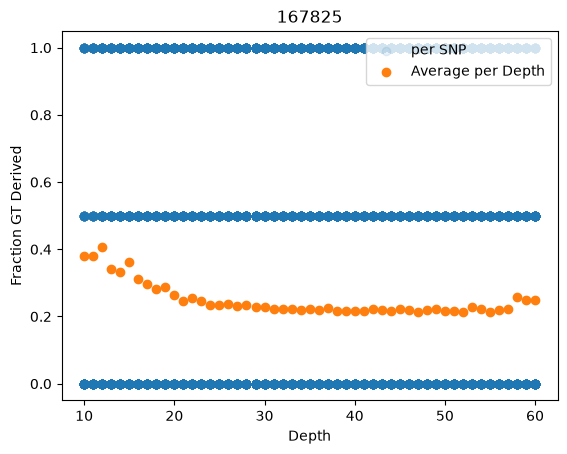

In [13]:
from scipy.stats import binned_statistic

plt.figure()
ax=plt.gca()

statistic, bin_edges, _ = binned_statistic(cov17, gt17/2, statistic='mean', bins=np.arange(200)-0.5)
bin_means = (bin_edges[1:]+bin_edges[:-1])/2

ax.scatter(cov17, gt17/2, alpha=0.1, label="per SNP")
ax.scatter(bin_means, statistic, label="Average per Depth")

ax.set_xlabel("Depth")
ax.set_ylabel("Fraction GT Derived")
ax.legend(loc="upper right")
ax.set_title("167825")
plt.show()

In [14]:
df.sort_values(by="depth")

,iid,depth
18,Bric037,24.438870
8,Bric015,25.414820
0,Bric001,27.395121
20,Bric040,28.877486
21,Bric042,29.926839
13,Bric024,31.198859
12,Bric023,31.579146
7,Bric011,33.428863
10,Bric021,33.542883
1,Bric002,33.893438


In [15]:
%%time
ph = ad_to_ph(ad, dp)

CPU times: user 54.7 ms, sys: 19 ms, total: 73.6 ms
Wall time: 72.1 ms


In [16]:
np.shape(ph)

(537048, 25)

In [17]:
### Sanity CheckL Derived Read Ratio
alts = np.sum(ph==1, axis=0)
refs = np.sum(ph==0, axis=0)

der_frac_full_ph = alts/ (refs + alts)
der_frac_full_ph

array([0.18510166, 0.20263745, 0.21368172, 0.24045861, 0.21774096,
       0.20826143, 0.20366464, 0.26499451, 0.2082199 , 0.22803956,
       0.22940877, 0.25555638, 0.25259451, 0.21563815, 0.1954477 ,
       0.22466328, 0.24008677, 0.2041994 , 0.23780534, 0.17686819,
       0.2478269 , 0.21824212, 0.17322972, 0.19590105, 0.12874045])

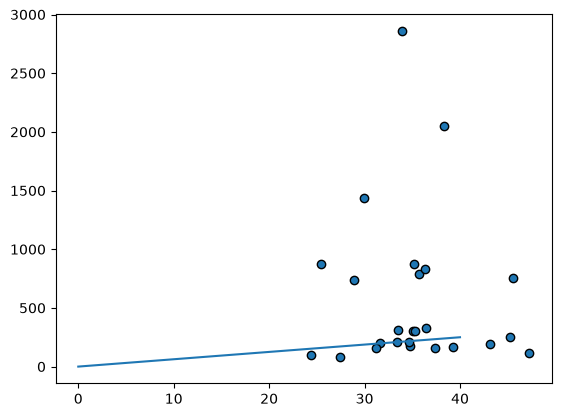

In [19]:
alts = np.sum(ad1[:,:,1], axis=0)
refs = np.sum(ad1[:,:,0], axis=0)

der_frac_full = alts/ (refs + alts)

df["alt_ratio_ph"] = der_frac_full_ph
df["alt_ratio"]  = der_frac_full
ad_max = np.max(ad1, axis=(0,2))
df["ad_max"]= ad_max
df.sort_values(by="depth")[:50]
plt.figure()
ax = plt.gca()
ax.scatter(df["depth"], df["ad_max"], edgecolor="k")
ax.plot([0,40],[0,250])
plt.show()

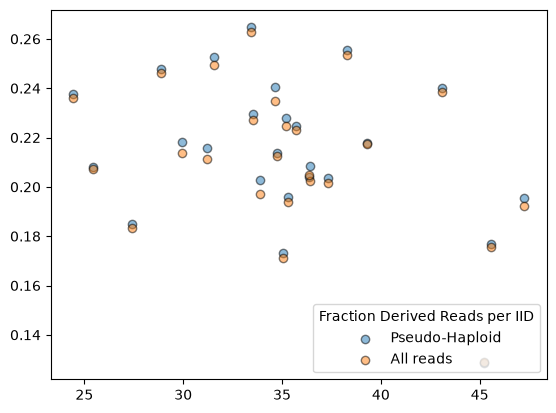

In [20]:
plt.figure()
ax = plt.gca()
ax.scatter(df["depth"], df["alt_ratio_ph"], edgecolor="k", label="Pseudo-Haploid", alpha=0.5)
ax.scatter(df["depth"], df["alt_ratio"], edgecolor="k", label="All reads", alpha=0.5)
ax.legend(loc="lower right", title="Fraction Derived Reads per IID")
plt.show()

### Fraction of derived reads in AD field

### Use Heterozygous markers

0.2034213


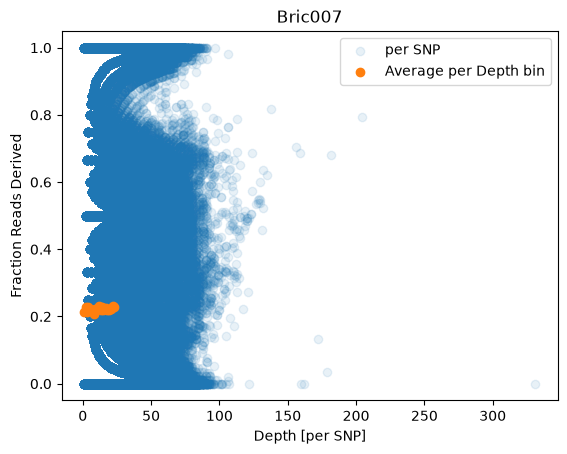

In [21]:
### High Depth IID
ad_hd = ad1[:,5,:]
hets = (ad_hd[:,0]>3) & (ad_hd[:,1]>3)
print(f"{np.mean(hets):.7f}")
ad_hets = ad_hd[hets]
np.mean(ad_hets, axis=0)

idx_iid = 5
a = ad1[:,idx_iid,:] # Select IID here
title = samples[idx_iid]

d = np.sum(a, axis=1) # Depth
idx = d>0
d_rate = a[idx,1]/d[idx]


### Plot
plt.figure()
ax=plt.gca()

statistic, bin_edges, _ = binned_statistic(d[idx], d_rate, statistic='mean', bins=np.arange(25)-0.5)
bin_means = (bin_edges[1:]+bin_edges[:-1])/2

ax.scatter(d[idx], d_rate, alpha=0.1, label="per SNP")
ax.scatter(bin_means, statistic, label="Average per Depth bin")
ax.set_xlabel("Depth [per SNP]")
ax.set_ylabel("Fraction Reads Derived")
ax.legend(loc="upper right")
ax.set_title(title)
plt.show()

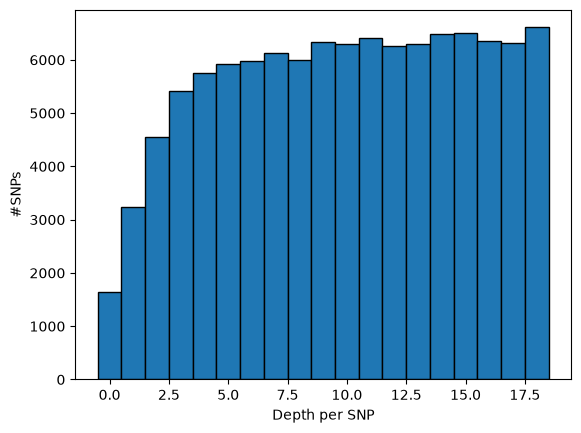

In [22]:
plt.figure()
ax = plt.gca()
ax.hist(d, bins=np.arange(0,20)-0.5, edgecolor="k")
ax.set_xlabel("Depth per SNP")
ax.set_ylabel("#SNPs")
plt.show()

In [23]:
idx1 = ph[:,0]>=0
idx2 = ph[:,1]>=0
idx = idx1 & idx2

np.mean(ph[idx,0] != ph[idx,1])

np.float64(0.1772706337766855)

In [24]:
pw_mm_rate(ph[:,0], ph[:,1], val_missing=-1)

(np.float64(0.1772706337766855), np.int64(95069), np.int64(536293))

In [25]:
%%time
df_pmr = pw_mm_rates_iids(gts=ph.T, iids=df["iid"], val_missing=-1)

CPU times: user 197 ms, sys: 16.4 ms, total: 213 ms
Wall time: 212 ms


In [26]:
np.mean(df_pmr["pmr"])

np.float64(0.2242062654952298)

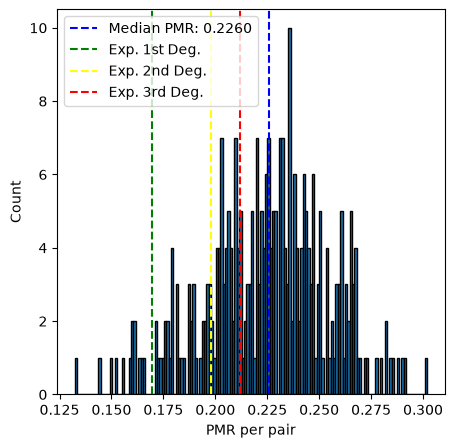

In [30]:
savepath=""

plt.figure(figsize=(5,5))
ax = plt.gca()
ax.hist(df_pmr["pmr"], bins=150, edgecolor="k")

#df_pmr1 = df_pmr[df_pmr["pmr"]>0.28]
df_pmr1 = df_pmr
m = np.median(df_pmr1["pmr"])
leg = f"Median PMR: {m:.4f}"
ax.axvline(m, ls="--", c="blue", label=leg)
ax.axvline(m*0.75, ls="--", c="green", label="Exp. 1st Deg.")
ax.axvline(m*0.875, ls="--", c="yellow", label="Exp. 2nd Deg.")
ax.axvline(m*(15/16), ls="--", c="red", label="Exp. 3rd Deg.")
ax.legend(loc="upper left")

ax.set_xlabel("PMR per pair")
ax.set_ylabel("Count")

if len(savepath)>0:
    plt.savefig(savepath, bbox_inches ='tight', pad_inches = 0, dpi=600)
    
plt.show()

In [31]:
df_pmr

,iid1,iid2,pmr,mms,snps
0,Bric001,Bric002,0.177271,95069,536293
1,Bric001,Bric003,0.196726,105634,536961
2,Bric001,Bric004,0.195278,104720,536261
3,Bric001,Bric005,0.178851,96020,536870
4,Bric001,Bric007,0.151939,81340,535347
...,...,...,...,...,...
295,Bric042,Bric044,0.227612,122228,537001
296,Bric042,Bric006,0.224897,120774,537018
297,Bric043,Bric044,0.160811,86354,536990
298,Bric043,Bric006,0.207178,111256,537007


In [32]:
unrelated = ['Bric002', 'Bric004', 'Bric008', 'Bric015', 'Bric023',
             'Bric031', 'Bric033', 'Bric034', 'Bric035', 'Bric039',
             'Bric040', 'Bric042', 'Bric044']

df_unrel = df_pmr[df_pmr['iid1'].isin(unrelated) & df_pmr['iid2'].isin(unrelated)]

print(f"{len(df_unrel)} pairs from {len(unrelated)} individuals")  # expect 78

78 pairs from 13 individuals


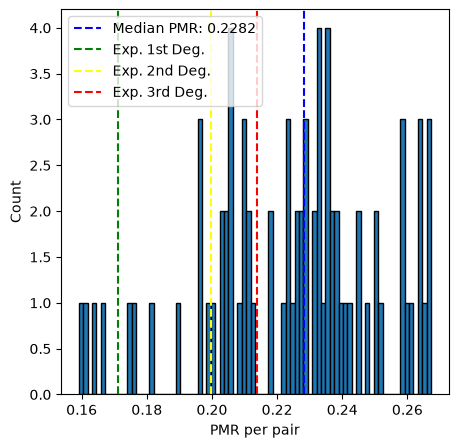

In [39]:
savepath=""

plt.figure(figsize=(5,5))
ax = plt.gca()
ax.hist(df_unrel["pmr"], bins=80, edgecolor="k")

#df_pmr1 = df_pmr[df_pmr["pmr"]>0.28]
df_pmr1 = df_unrel
m = np.median(df_pmr1["pmr"])
leg = f"Median PMR: {m:.4f}"
ax.axvline(m, ls="--", c="blue", label=leg)
ax.axvline(m*0.75, ls="--", c="green", label="Exp. 1st Deg.")
ax.axvline(m*0.875, ls="--", c="yellow", label="Exp. 2nd Deg.")
ax.axvline(m*(15/16), ls="--", c="red", label="Exp. 3rd Deg.")
ax.legend(loc="upper left")

ax.set_xlabel("PMR per pair")
ax.set_ylabel("Count")

if len(savepath)>0:
    plt.savefig(savepath, bbox_inches ='tight', pad_inches = 0, dpi=600)
    
plt.show()

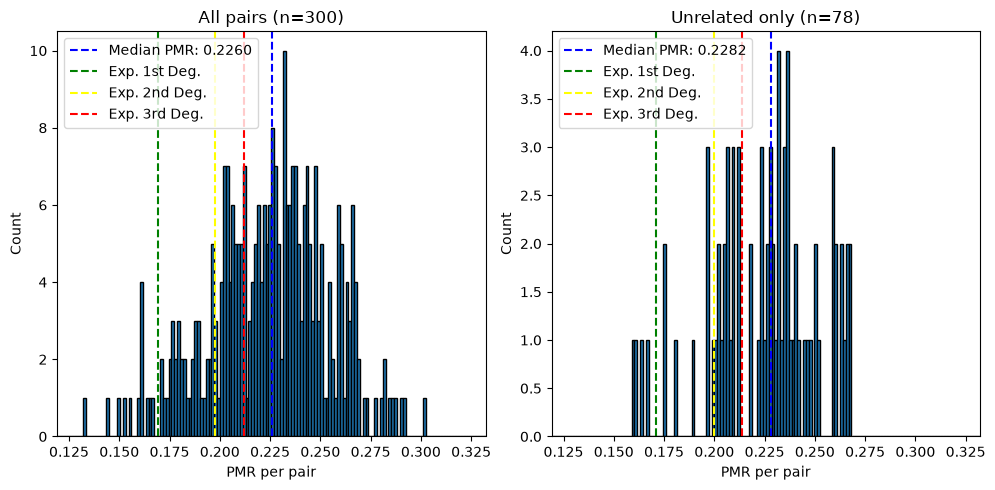

In [41]:
savepath = ""

xmin = df_pmr["pmr"].min() * 0.9
xmax = df_pmr["pmr"].max() * 1.1

def plot_pmr(ax, data, median_from, bins, title):
    ax.hist(data["pmr"], bins=bins, range=(xmin, xmax), edgecolor="k")
    m = np.median(median_from["pmr"])
    ax.axvline(m, ls="--", c="blue", label=f"Median PMR: {m:.4f}")
    ax.axvline(m * 0.75,    ls="--", c="green",  label="Exp. 1st Deg.")
    ax.axvline(m * 0.875,   ls="--", c="yellow", label="Exp. 2nd Deg.")
    ax.axvline(m * (15/16), ls="--", c="red",    label="Exp. 3rd Deg.")
    ax.legend(loc="upper left")
    ax.set_xlabel("PMR per pair")
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.set_xlim(xmin, xmax)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

plot_pmr(axes[0], df_pmr,   df_pmr,   bins=150,
         title=f"All pairs (n={len(df_pmr)})")
plot_pmr(axes[1], df_unrel, df_unrel, bins=150,
         title=f"Unrelated only (n={len(df_unrel)})")

plt.tight_layout()

if len(savepath) > 0:
    plt.savefig(savepath, bbox_inches='tight', pad_inches=0, dpi=600)

plt.show()

In [42]:
ph

array([[0, 0, 1, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 1, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 1, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [1, 1, 0, ..., 1, 0, 0]], shape=(537048, 25), dtype=int8)